# Coursework 2 - Mathematics for Machine Learning

## Due: 12/12/2025

## CID: 02518058

***
***

## Exercise 1: Approximation theory

### Exercise 1.1

#### Question 1:

The original network $f(x)$ can be written as a sum of $w$ neurons:

$$
 f(x) = \sum_{k=1}^w A_2^{(k)} \sigma(A_1^{(k)} x + b_1^{(k)})
$$

where

- $A_1^{(k)}$: The $k$-th row of matrix $A_1$, the weights connect the input layer to the hidden layer.
- $b_1^{(k)}$: The $k$-th element of bias vector $b_1$.
- $A_2^{(k)}$: The $k$-th element of matrix $A_2$, the weights which connect the hidden layer to the output.

**Construct network $N$ with $w$ hidden layers**

At any hidden layer $k$, the neurons represent a vector $h^{(k)} \in \mathbb{R}^{d+3}$ containing four components

$$
h^{(k)} = [x^{(k)}, P^{(k)}, M^{(k)}, z^{(k)}]^\top
$$

where

- $x^{(k)} \in \mathbb{R}^d$: Store input $x$. Because $x\in [0,1]^d$,  the values are non-negative, it can pass through ReLU with identity mapping $\sigma(x)=x$
- $P^{(k)} \in \mathbb{R}$: Store positive part of the partial sum.
- $M^{(k)} \in \mathbb{R}$: Store negative part of the partial sum.
- $z^{(k)} \in \mathbb{R}$: Store the activation of the $k$-th ReLU output

**At layer $k=1$:**

Compute the first term and initialise accumulators to $0$

$$
h^{(1)}=[x,0,0,z^{(1)}]^\top
$$

- $x^{(1)} = x$
- $P^{(1)} = 0$
- $M^{(1)} = 0$
- $z^{(1)} = \sigma(A_1^{(1)} x + b_1^{(1)})$
    - Where $A_1^{(1)}$ is the 1st rows of $A_1$

The first hidden map is

$$
h^{(1)} = \sigma(W_{in} x + \beta_{in})
$$

Where

$$
W_{in} =
\begin{bmatrix}
I_d \\
0 \\
0 \\
A_1^{(1)}
\end{bmatrix},
\quad
\beta_{in} =
\begin{bmatrix}
0 \\
0 \\
0 \\
b_1^{(1)}
\end{bmatrix}
$$

**At hidden layers $k=2,\dots w$:**

Since the weights $A_2$ can be negative, a single running sum might become negetive, ReLU would destory the accumulated information. To prevent this, split the previous weight $A_2^{(k-1)}$ into positive and negative parts:

$$
c^+ = \max(0, A_2^{(k-1)}), \quad c^- = \max(0, -A_2^{(k-1)})
$$

The update rules for layer $k$ are:

- Copy input:
    
    $$
    x^{(k)} = \sigma(x^{(k-1)}) = x
    $$
    
- Update positive sum:
    
    $$
    P^{(k)} = \sigma(P^{(k-1)} + c^+ \cdot z^{(k-1)})
    $$
    
- Update negative sum:
    
    $$
    M^{(k)} = \sigma(M^{(k-1)} + c^- \cdot z^{(k-1)})
    $$
    
- Compute new activation
    
    $$
    z^{(k)} = \sigma(A_1^{(k)} x^{(k-1)} + b_1^{(k)})
    $$
    

Hence, $k$ hidden map updates the state using the parameters from the previous term $A_2^{(k-1)}$ to accumulate, and the current parameters $A_1^{(k)}, b_1^{(k)}$ to compute the new activation, something like

$$
h^{(k)}=\sigma(W_k h^{(k-1)}+\beta_k)
$$

Where $W_k$ is the weight matrix and $\beta_k$ is the bias matrix

$$
W_k =
\begin{bmatrix}
I_d & 0 & 0 & 0 \\
0 & 1 & 0 & c^+_{k-1} \\
0 & 0 & 1 & c^-_{k-1} \\
A_1^{(k)} & 0 & 0 & 0
\end{bmatrix},
\quad
\beta_k =
\begin{bmatrix}
0 \\
0 \\
0 \\
b_1^{(k)}
\end{bmatrix}
$$

**At output layer:**

- **$P^{(w)}$ and $M^{(w)}$** contain the sum of terms from $1$ to $w-1$.
- **$z^{(w)}$** has just been calculated in this final layer. It has not yet been added to the accumulators because there is no Layer $w+1$.
- Since the output layer is linear, no ReLU, we can just multiply $z^{(w)}$ by weight $A_2^{(w)}$

Therefore:

$$
\begin{aligned}
N(x) &= P^{(w)} - M^{(w)} + A_2^{(w)} z^{(w)} \\
&= \left( \sum_{k=1}^{w-1} A_2^{(k)} z^{(k)} \right) + A_2^{(w)} z^{(w)} \\
&= \sum_{k=1}^{w} A_2^{(k)} \sigma(A_1^{(k)} x + b_1^{(k)}) \\
&= f(x)
\end{aligned}
$$

#### Question 2:

The input now contain negative values. Information will be lost if negative values pass through the ReLU function.

To fix this, we simply shift the inputs such that they are non-negative.

In the first hidden layer, we store a shifted version $\tilde{x} = x + 1$

Since $x \in [-1, 1]^d$, we have $\tilde{x} \in [0, 2]^d$. Because these values are non-negative, they pass through ReLU layers unchanged:

$$
\sigma(\tilde{x}) = \tilde{x}
$$

When computing the term $z^{(k)} = \sigma(A_1^{(k)} x + b_1^{(k)})$, substitute $x = \tilde{x} - 1$:

$$
A_1^{(k)} x + b_1^{(k)} = A_1^{(k)} (\tilde{x} - 1) + b_1^{(k)} = A_1^{(k)} \tilde{x} + (b_1^{(k)} - A_1^{(k)} 1)
$$

The network simply uses a original weights $A_1^{(k)}$ acting on $\tilde x$ and a modified bias term $(b_1^{(k)} - A_1^{(k)} 1)$ to calculate the correct value.

Hence, by encoding the input as $\tilde{x} = x + 1$, we can still use $d$ nodes to store $\tilde{x}$, and the same number of nodes for accumulators and activation value, so in total, I still need $d+3$ nodes.

***
### Exercise 1.2

#### Question 1:

Given the target function

$$
h(x) =  x f'(wx)
$$

Take derivative of network $f(wx)$

$$
 \frac{d}{dw} f(wx) = f'(wx) \cdot \frac{d}{dw}(wx) = x f'(wx) = h(x)
$$

Write $h$ as limit of the derivative

$$
 h(x) = \lim_{\delta \to 0} \frac{f((w+\delta)x) - f(wx)}{\delta}
$$

For a fixed small $\delta \ne0$, define a candidate function

$$
 g(x) = \frac{f((w+\delta)x) - f(wx)}{\delta}
$$

Since $f\in\mathcal{F}_{\sigma,1}$, the functions $x \mapsto f(wx)$  and $x \mapsto f((w+\delta)x)$ are also in $\mathcal{F}_{\sigma,1}$.

Also since $\mathcal{F}_{\sigma,1}$ is closed under addition and scalar multiplication, we have the linear combination $g\in\mathcal{F}_{\sigma,1}$

For each fixed $x \in [0,1]$, apply Taylor’s expansion to the term $f((w+\delta)x)$ around the point $wx$

$$
 f(wx + \delta x) = f(wx) + f'(wx)(\delta x) + \frac{1}{2}f''(c)(\delta x)^2
$$

where $c$ is some number between $wx$ and $wx+\delta x$.

Substitute this expansion back into $g(x)$:

$$
 g(x) = \frac{\left[ f(wx) + \delta x f'(wx) + \frac{1}{2}f''(c)(\delta x)^2 \right] - f(wx)}{\delta}  
\\= x f'(wx) + \frac{\delta}{2} x^2 f''(c)
$$

Since $h(x)=x f'(wx)$, the pointwise error is

$$
 |h(x) - g(x)| = \left| \frac{\delta}{2} x^2 f''(c) \right|
$$

Since $x \in [0,1]$, we know $|x^2| \leq 1$.

Since $c$ lies between $wx$ and $(w+\delta)x$, assume WLOG that $|\delta | \le 1$, it is always inside the compact interval

$$
I = [-|w|-1, |w|+1]
$$

Since $f \in C^\infty$ is smooth, its second derivative $f''$ is continuous. A continuous function on a compact interval is bounded, by extreme value theorem, it must attain a maximum $M$

$$
M=\max_{y\in I}|f''(y)| < \infty
$$

Hence, the uniform norm is bounded by

$$
 \|h - g\|_u = \sup_{x \in [0,1]} |h(x) - g(x)| \leq \frac{|\delta|}{2} \cdot 1 \cdot M
$$

To ensure the error is less than $\epsilon$, choose  

$$
0<|\delta| < \min (1,\frac{2\epsilon}{M} )
$$

such that the uniform error bound becomes

$$
\|h - g\|_u \le \frac{M |\delta|}{2} < \frac{M}{2} \cdot \frac{2\epsilon}{M} = \epsilon
$$

Hence, we have found a function $g \in \mathcal{F}_{\sigma,1}$ that approximates $h$ within $\epsilon$.

#### Question 2:

**For base case  $n=1$:**

The target function is

$$
 h_{1,w,b}(x) = x^1 \sigma^{(1)}(wx+b) = x \sigma'(wx+b)
$$

Define a function $f \in F_{\sigma,1}$ as

$$
f(wx)=\sigma(wx+b)
$$

Then take derivative with respect to $w$

$$
\frac{d}{dw}f(wx)=xf'(wx)=x\sigma'(wx+b)= h_{1,w,b}(x)
$$

From quesion 1, we proved that for any $f \in \mathcal{F}_{\sigma,1}$ and any $\epsilon > 0$, $\exists g \in \mathcal{F}_{\sigma,1}$ such that

$$
\|x f'(wx) - g\|_u < \epsilon
$$

Therefore, $h_{1,w,b}$ can be approximated by a function in $\mathcal{F}_{\sigma,1}$, so the base case holds.

**Induction hypothesis**

Assume that for a fixed interger $n=k$, for any real $w,b\in\mathbb{R}$ and any tolerance $\gamma>0$,  there exists $g_k\in\mathcal{F}_{\sigma,1}$ such that

$$
\|h_{k,w,b}-g_k\|_u<\gamma
$$

**For indutive step $n=k+1$**

We want to show that for any $w,b,\epsilon$, there exists $g\in\mathcal{F}_{\sigma,1}$ approximating

$$
h_{k+1,w,b}(x) = x^{k+1} \sigma^{(k+1)}(wx+b)
$$

First we show that for a fixed $x$:

$$
\frac{d}{dw} h_{k,w,b}(x) = \frac{d}{dw} \left[ x^k \sigma^{(k)}(wx+b) \right] = x^k \cdot \frac{d}{dw} \sigma^{(k)}(wx+b)
$$

Using this chain rule

$$
\frac{d}{dw}\sigma^{(k)}(wx+b) = x\sigma^{(k+1)}(wx+b)
$$

We get

$$
\frac{d}{dw} h_{k,w,b}(x) = x^k \cdot x \sigma^{(k+1)}(wx+b) = x^{k+1} \sigma^{(k+1)}(wx+b) = h_{k+1,w,b}(x)
$$

So the target function $h_{k+1}$ is the derivative of $h_k$ with respect to $w$.

We again approximate this derivative using a finite difference quotient with pertubed $w+\delta$ at fixed $x$.

$$
h_{k+1,w,b}(x)  = \lim_{\delta \to 0} \frac{h_{k, w+\delta, b}(x) - h_{k, w, b}(x)}{\delta}
$$

For a fixed small $\delta \ne0$, define the finite difference function

$$
g_{k+1}(x) = \frac{h_{k, w+\delta, b}(x) - h_{k, w, b}(x)}{\delta}
$$

Split the uniform error bound into two parts for any $g \in \mathcal{F}_{\sigma,1}$ and apply triangle inequality

$$
 \|h_{k+1,w,b} - g\|_u \leq \|h_{k+1,w,b} - g_{k+1}\|_u + \|g_{k+1} - g\|_u
$$

For the first term:

Fix an arbitrary $x \in [0,1]$ and view $h_{k, w, b}(x)$ as a function of the parameter $w$. Calculate second derivative:

$$
\frac{d^2}{dw^2} h_{k, w, b}(x) = \frac{d}{dw} h_{k+1, w, b}(x) = x^{k+1} \cdot x \sigma^{(k+2)}(wx+b) = h_{k+2, w, b}(x)
$$

Apply Taylor’s theorem around $w$

$$
h_{k, w+\delta, b}(x) = h_{k, w, b}(x) + \delta \cdot h_{k+1, w, b}(x) + \frac{\delta^2}{2} h_{k+2, c_x, b}(x)
$$

where $c_x$ is some value between $w$ and $w+\delta$.

Substitute into $g_{k+1}(x)$

$$
g_{k+1}(x) = \frac{\delta \cdot h_{k+1, w, b}(x) + \frac{\delta^2}{2} h_{k+2, c_x, b}(x)}{\delta} = h_{k+1, w, b}(x) + \frac{\delta}{2} h_{k+2, c_x, b}(x)
$$

Thus, the pointwise error is:

$$
|h_{k+1, w, b}(x) - g_{k+1}(x)| = \left| \frac{\delta}{2} h_{k+2, c_x, b}(x) \right| = \frac{|\delta|}{2} |x^{k+2}| \left| \sigma^{(k+2)}(c_x x + b) \right|
$$

Since $x \in [0,1]$, we have $|x^{k+2}| \le 1$.

Assume WLOG that $|\delta| \le 1$. Then $c_x$ lies in the interval $[w-1, w+1]$. Consequently, the argument of the activation function, $y = c_x x + b$, lies within the compact set:

$$
K = [-(|w|+1) - |b|, \ (|w|+1) + |b|]
$$

because $|c_x x + b| \le |c_x| + |b| \le |w| + 1 + |b|$.

Since $\sigma \in C^\infty$, the derivative $\sigma^{(k+2)}$ is continuous and thus bounded on the compact set $K$,  it must attain a maximum $M$

$$
 M = \max_{y \in K} |\sigma^{(k+2)}(y)| < \infty
$$

Therefore, taking the supremum over $x \in [0,1]$, we obtain the uniform bound

$$
\|h_{k+1, w, b} - g_{k+1}\|_u \le \frac{|\delta|}{2} \cdot 1 \cdot M
$$

To ensure the error is less than $\epsilon/2$, choose  

$$
0<|\delta| < \min (1,\frac{\epsilon}{M} )
$$

such that the uniform error bound becomes

$$
\|h_{k+1, w, b} - g_{k+1}\|_u  \le \frac{|\delta|}{2} M < \frac{\epsilon}{2}
$$

For the second term, by the inductive hypothesis,

$$
\exists g_1 \in \mathcal{F}_{\sigma,1} \quad \text{s.t.} \quad \|h_{k, w+\delta, b} - g_1\|_u < \frac{\epsilon |\delta|}{4}
\\
\exists g_2 \in \mathcal{F}_{\sigma,1} \quad \text{s.t.} \quad \|h_{k, w, b} - g_2\|_u < \frac{\epsilon |\delta|}{4}
$$

We can define candidate function $g$ as

$$
g(x) = \frac{g_1(x)-g_2(x)}{\delta}
$$

Since $\mathcal{F}_{\sigma,1}$ is closed under addition and scalar multiplication, then $g\in F_{\sigma,1}$.

Thus, the error for second term is

$$
\begin{aligned} \|g_{k+1} - g\|_u &= \left\| \frac{h_{k, w+\delta, b} - g_1}{\delta} - \frac{h_{k, w, b} - g_2}{\delta} \right\|_u \\ &\leq \frac{1}{|\delta|} \left( \|h_{k, w+\delta, b} - g_1\|u + \|h_{k, w, b} - g_2\|_u \right) \\ &\leq \frac{1}{|\delta|} \left( \frac{\epsilon |\delta|}{4} + \frac{\epsilon |\delta|}{4} \right) = \frac{\epsilon}{2} \end{aligned}
$$

Combining both terms:

$$
 \|h_{k+1,w,b} - g\|_u < \frac{\epsilon}{2} + \frac{\epsilon}{2} = \epsilon
$$

Thus, the hypopthesis holds for $n=k+1$. By induction, it holds for all positive integers $n$.

#### Question 3:

Fix any integer $n \ge 1$. Suppose for a contradiction that $\sigma^{(n)}(x)=0$  for all $x$. Integrating $n$ times implies that $\sigma(x)$ is a polynomial of degree at most $n-1$. However, since the given $\sigma$ is not a polynomial, there exists $b^* \in \mathbb{R}$ such that

$$
C=\sigma^{(n)}(b^*) \ne 0
$$

where $C$ is a non-zero constant.

Consider the target function defined in question 2,

$$
h_{n,w,b}(x) = x^n \sigma^{(n)}(wx+b)
$$

For any real $w,b\in\mathbb{R}$, we are free to choose the following parameters

$$
w=0, \quad b=b^*
$$

Substitute into the target function, it becomes

$$
\begin{aligned}
h_{n,0,b^*}(x) &= x^n \sigma^{(n)}(0 \cdot x + b^*) \\
&= x^n \sigma^{(n)}(b^*) \\
&= C x^n
\end{aligned}
$$

Using the result from question 2, for any tolerance $\gamma > 0$ , there exists a network $\tilde{g} \in \mathcal{F}_{\sigma,1}$ such that

$$
 \| h_{n,0,b^*} - \tilde{g} \|_u < \gamma \\
 \| C x^n - \tilde{g} \|_u < \gamma
$$

Choose tolerance $\gamma = \epsilon |C|$. Since $C \neq 0$, $|C| > 0$, so

$$
 \| C x^n - \tilde{g} \|_u < \epsilon |C|
$$

Define new network as

$$
 g(x) = \frac{1}{C} \tilde{g}(x)
$$

Since $\mathcal{F}_{\sigma,1}$ is closed under scalar multiplication, $g \in \mathcal{F}_{\sigma,1}$.

Threfore, the uniform error is

$$
\begin{aligned}
\| p_n - g \|_u &= \left\| x^n - \frac{1}{C}\tilde{g} \right\|_u \\
&= \left\| \frac{1}{C} (C x^n - \tilde{g}) \right\|_u \\
&= \frac{1}{|C|} \| C x^n - \tilde{g} \|_u
\\&< \frac{1}{|C|} (\epsilon |C|) = \epsilon
\end{aligned}
$$

#### Question 4:

Apply triangle inequality to split the error bound into Taylor approximation error and the network approximation error

$$
\sup_{|x|\leq r} |\exp(x) - g(x)| \leq \sup_{|x|\leq r} |\exp(x) - P_N(x)| + \sup_{|x|\leq r} |P_N(x) - g(x)|
$$

We know the Maclaurin series expansion for $e^x$ is the infinite sum

$$
\exp(x) = \sum_{k=0}^\infty \frac{x^k}{k!}
$$

This series converges uniformly on any compact interval. Therefore, for the specific interval $[-r,r]$ and for any $\epsilon>0$ there exists a sufficiently large $N \in \mathbb{N}$ such that the partial sum

$$
 P_N(x) = \sum_{k=0}^N \frac{1}{k!} x^k
$$

approximates $\exp(x)$ uniformly within an error of $\epsilon / 2$

$$
 \sup_{|x| \le r} |\exp(x) - P_N(x)| < \frac{\epsilon}{2}
$$

$P_N(x)$ is a linear combinations of monomial $x^k$. Let  

$$
P_N(x) = \sum_{k=0}^N c_k x^k, \quad c_k=1/k!
$$

In Question 3, we proved that for any $n$, the monomial $x^n$ can be uniformly approximated by a network in $\mathcal{F}_{\sigma,1}$ on the interval $[0,1]$. So far the proofs in question 1 to 3 rely on the compactness of the domain, which guarantees that the continuous derivatives of the smooth function $\sigma$ are bounded.

Since $[-r, r]$ is also a compact interval, the derivatives are also bounded on $[-r, r]$, so we just need to extend results to $[-r, r]$. Therefore, for each $k \in \{0, 1, \dots, N\}$ and any tolerance $\gamma_k > 0$, there exists $g_k \in \mathcal{F}_{\sigma,1}$ such that

$$
 \sup_{|x| \le r} |x^k - g_k(x)| < \gamma_k
$$

Now choose the tolerance for each term such that the total error sums to less than $\frac{\epsilon}{2}$.

Let $A = \sum_{k=0}^N |c_k|$. Note that since $c_0=1/0!=1$, we have $A \ge 1$, so $A \ne 0$. Choose:  

$$
\gamma_k = \frac{\epsilon}{2A}
$$

Define a candidate network $g$ as a linear combination of the monomial approximations

$$
 g(x) = \sum_{k=0}^N c_k g_k(x)
$$

Since $\mathcal{F}_{\sigma,1}$ is closed under addition and scalar multiplication, $g \in \mathcal{F}_{\sigma,1}$.

Now bound the error between the polynomial $P_N$ and the network $g$:

$$
\begin{aligned}
\sup_{|x| \le r} |P_N(x) - g(x)| &= \sup_{|x| \le r} \left| \sum_{k=0}^N c_k x^k - \sum_{k=0}^N c_k g_k(x) \right| \\
&\le \sum_{k=0}^N |c_k| \sup_{|x| \le r} |x^k - g_k(x)| \\
&< \sum_{k=0}^N |c_k| \frac{\epsilon}{2A} \\
&= \frac{\epsilon}{2A} \left( \sum_{k=0}^N |c_k| \right)
= \frac{\epsilon}{2A}\cdot A=\frac{\epsilon}{2}
\end{aligned}
$$

Combining the bounds

$$
 \sup_{|x|\leq r} |\exp(x) - g(x)| < \frac{\epsilon}{2} + \frac{\epsilon}{2} = \epsilon
$$

Thus, $\exists g \in \mathcal{F}_{\sigma,1}$ that approximates $\exp(x)$ within $\epsilon$ on the interval $[-r, r]$.

#### Question 5:

We want to show that $\mathcal{F}_{\sigma,d}$ is dense in $(C([0,1]^d;\mathbb{R}),\|\cdot\|_u)$ so that $\mathcal{F}$ is a universal approximator over a compact set $[0,1]^d$.

Let $f \in C([0,1]^d)$ be any continuous target function and let $\epsilon > 0$.

Apply triangle Inequality:

$$
 \|f - g\|_u \leq \|f - h\|_u + \|h - g\|_u
$$

where:

- $h \in \mathcal{F}_{\exp,d}$ is an approximation of $f$
- $g \in \mathcal{F}_{\sigma,d}$ is an approximation of $h$

By Lemma 4.9, $\mathcal{F}_{\exp,d}$ is a universal approximator. Therefore, there exists a function $h \in \mathcal{F}_{\exp,d}$ such that

$$
 \|f - h\|_u < \frac{\epsilon}{2}
$$

Function $h$ in $\mathcal{F}_{\exp,d}$ take the form

$$
 h(x) = \sum_{k=1}^N a_k \exp(w_k^\top x+b_k)
$$

where

- $a_k \in \mathbb{R}$ is the output weights
- $w_k \in \mathbb{R}^d$ is the input weights vector
- $b_k \in \mathbb{R}$ is the biases

Since $\mathcal{F}_{\sigma,d}$ is closed under addition and scalar multiplication, we can approximate each term $\exp(w_k^\top x+b_k)$  individually.

For each $k \in \{1, \dots, N\}$, the affine map $y_k(x)=w_k^\top x+b_k$ maps the compact domain $[0,1]^d$ to a compact interval $[-R_k,R_k] \subset \mathbb{R}$ where

$$
R_k = \sup_{x \in [0,1]^d} |w_k^\top x+b_k| < \infty
$$

Let $A = \sum_{k=1}^N |a_k|$

- Case 1: If $A=0$, then $h = 0$, which is trivially in $\mathcal{F}_{\sigma,d}$.
- Case 2: If $A > 0$, then define a uniform tolerance as

$$
\delta = \frac{\epsilon}{2A}
$$

From Question 4, for each $k$, there exists a network $g_k \in \mathcal{F}_{\sigma,1}$ such that:

$$
 \sup_{|y| \le R_k} |\exp(y) - g_k(y)| < \delta
$$

Now define the final candidate function $g$ as

$$
g(x) = \sum_{k=1}^N a_k g_k(w_k^\top x+b_k)
$$

Since each $g_k \in \mathcal{F}_{\sigma,1}$, it has the form

$$
g_k(y) = \sum_j \alpha_{k,j} \sigma(u_{k,j} y + v_{k,j})
$$

Then substitute $y=w_k^\top x+b_k$

$$
\begin{aligned}
g_k(w_k^\top x + b_k) &= \sum_j \alpha_{k,j} \sigma( u_{k,j} (w_k^\top x + b_k) + v_{k,j} ) \\&= \sum_j \alpha_{k,j} \sigma( (u_{k,j} w_k)^\top x + (u_{k,j} b_k + v_{k,j}) )
\end{aligned}
$$

This is still a linear combination of the form $\sigma(W^\top x+b)$. Since $\mathcal{F}_{\sigma,d}$ is closed under addition and scalar multiplication, the final sum $g \in \mathcal{F}_{\sigma,d}$.

Now bound the uniform error

$$
\begin{aligned}
\|h - g\|_u &= \sup_{x \in [0,1]^d} \left| \sum_{k=1}^N a_k \left( \exp(w_k^\top x + b_k) - g_k(w_k^\top x + b_k) \right) \right| \\
&\leq \sum_{k=1}^N |a_k| \sup_{|y| \le R_k} |\exp(y) - g_k(y)| \\
&< \sum_{k=1}^N |a_k| \delta \\
&= \left( \sum_{k=1}^N |a_k| \right) \frac{\epsilon}{2A} = A \cdot \frac{\epsilon}{2A} = \frac{\epsilon}{2}
\end{aligned}
$$

Combining the bounds:

$$
 \|f - g\|_u \leq \|f - h\|_u + \|h - g\|_u < \frac{\epsilon}{2} + \frac{\epsilon}{2} = \epsilon
$$

Thus, for any continuous function $f$ and $\epsilon > 0$, $\exists g \in \mathcal{F}_{\sigma,d}$ that approximates it within $\epsilon$. This proves that $\mathcal{F}_{\sigma,d}$ is dense in $C([0,1]^d)$, making it a universal approximator.

#### Question 6:

Assume $\sigma$ is a polynomial of degree $N \in \mathbb{N} \cup \{0\}$.

Any function $g \in \mathcal{F}_{\sigma,1}$ is a linear combination of these neurons

$$
 g(x) = \sum_{k=1}^m a_k \sigma(w_k x + b_k)
$$

Consider a single term $\sigma(w_k x + b_k)$. Since the argument $w_k x + b_k$ is a polynomial of degree at most 1, and $\sigma$ is a polynomial of degree $N$, their composition is a polynomial of degree at most $N \cdot 1 = N$.

Since the sum of polynomials of degree at most $N$ is itself a polynomial of degree at most $N$, then $g \in \mathcal{F}_{\sigma,1}$ is a polynomial of degree at most $N$.

Let $\mathcal{P}_N$ denote the vector space of polynomials of degree at most $N$, we have shown that

$$
 \mathcal{F}_{\sigma,1} \subseteq \mathcal{P}_N
$$

Consider target function $f \in C([0,1])$

$$
f(x) = x^{N+1}
$$

Note that $f(x)$ is a polynomial of degree $N+1$, so $f \notin \mathcal{P}_N$.

The space $\mathcal{P}_N$ has a finite basis $\{1, x, x^2, \dots, x^N\}$. It is a finite-dimensional subspace of the normed vector space $(C([0,1]), \|\cdot\|_u)$, so $\mathcal{P}_N$ is closed.

Since $\mathcal{P}_N$ is closed and $f \notin  \mathcal{P}_N$, there exist a strictly positive distance $\delta$ between $f$ and $\mathcal{P}_N$

$$
\delta = \inf_{p \in \mathcal{P}_N} \|f - p\|_u > 0
$$

Since  $\mathcal{F}_{\sigma,1} \subseteq \mathcal{P}_N$ , this implies that for any network $g \in \mathcal{F}_{\sigma,1}$:

$$
\|f-g\|_u \ge \delta
$$

If $\mathcal{F}_{\sigma,1}$ were a universal approximator, then it must be dense in $(C([0,1];\mathbb{R}),\|\cdot\|_u)$. This implies that for any $\epsilon > 0$ , $\exists g \in \mathcal{F}_{\sigma,1}$ such that

$$
\|f-g\|_u < \epsilon
$$

However, if we choose $\epsilon = \delta /2$ , then no such function exists.

This contradicts the definition of universal approximator. Therefore, $\mathcal{F}_{\sigma,1}$ is not a universal approximator.

***
***

## Exercise 2: Implementation

### Part 1: Image classification


### Question 1
Enter your answer here

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import os
from torchsummary import summary

In [8]:
if torch.cuda.is_available():
    print('Using GPU')
    device = torch.device('cuda')
else:
    print('Using CPU')
    device = torch.device('cpu')

Using CPU


In [3]:
# Import the dataset
if not os.path.exists("Linnaeus_5_dataset"):
  !wget "https://chaladze.com/l5/img/Linnaeus%205%2032X32.rar"
  !mkdir -p Linnaeus_5_dataset
  !unrar x "Linnaeus 5 32X32.rar" Linnaeus_5_dataset/ > /dev/null

--2025-12-10 19:47:15--  https://chaladze.com/l5/img/Linnaeus%205%2032X32.rar
Resolving chaladze.com (chaladze.com)... 162.241.216.47
Connecting to chaladze.com (chaladze.com)|162.241.216.47|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15544998 (15M) [application/x-rar-compressed]
Saving to: ‘Linnaeus 5 32X32.rar’

Linnaeus 5 32X32.ra 100%[===================>]  14.82M  25.4MB/s    in 0.6s    

2025-12-10 19:47:15 (25.4 MB/s) - ‘Linnaeus 5 32X32.rar’ saved [15544998/15544998]



In [4]:
# Load the dataset
dataset = './Linnaeus_5_dataset/Linnaeus 5 32X32'

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.ImageFolder(root=os.path.join(dataset, 'train'), transform=transform)
testset = torchvision.datasets.ImageFolder(root=os.path.join(dataset, 'test'), transform=transform)
classes = trainset.classes


transforms.Compose()

- It combine several image preprocessing steps into one operation. Each transform is applied in order to the input image
- It produces a function that does: output = T3(T2(T1(input)))
- For example, apply `ToTensor` first, then pass that result into `Normalize`.


transforms.ToTensor()

- It convert a PIL image or numpy array into a pytorch tensor
- It rearrange dimension from (Height, Width, Channels) to pytorch format (Channels, Height, Width)
- It scales pixel values from [0, 255] to [0.0, 1.0] and changes the data type from integers to floating-points


transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))

- It shifts and scales the pixel values using the formula:
    
  $$
  \text{output} = \frac{\text{input} - \text{mean}}{\text{standard deviation}}
  $$
    
  where
  - mean = (0.5, 0.5, 0.5) to each RGB channel
  - std = (0.5, 0.5, 0.5)

- It transform the input [0, 1] to [-1, 1]
    - input = 1.0, output = (1 - 0.5)/0.5 = 1.0
    - input = 0.0, output = (0 - 0.5)/0.5 = -1.0
- It helps neural networks train faster and provide stability when the input data is centered around zero.
    - If inputs are all positive (0 to 1), the gradients during backpropagation can zigzag inefficiently.

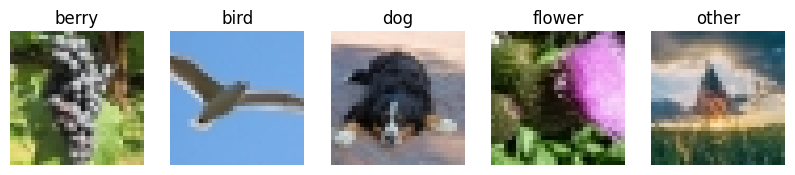

In [5]:
def plot_images(dataset):

    class_names = dataset.classes
    fig, axes = plt.subplots(1, 5, figsize=(10, 4))
    loader = torch.utils.data.DataLoader(dataset, batch_size=1, shuffle=True)
    found_classes = set()

    for img, label in loader:
        idx = label.item()
        if idx not in found_classes:
            found_classes.add(idx)

            # Undo normalisation
            image = img[0] * 0.5 + 0.5

            # Convert PyTorch dims: (C, H, W) to (H, W, C) for Matplotlib
            image = image.permute(1, 2, 0)

            # Plot image for this class
            axes[idx].imshow(image)
            axes[idx].set_title(class_names[idx])
            axes[idx].axis('off')

        if len(found_classes) == 5:
            break

    plt.show()

plot_images(trainset)

### Question 2

In [12]:
class myCNN(nn.Module):
    def __init__(self):
        super(myCNN, self).__init__()

        # Define convolutional layers
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)

        # Define batchnorm
        self.bn1 = nn.BatchNorm2d(32)
        self.bn2 = nn.BatchNorm2d(64)
        self.bn3 = nn.BatchNorm2d(128)

        # Define pooling layer
        # It pools together 2x2 of the inputs by keeping only the maximum value
        # and uses a stride of 2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Define fully connected layers
        self.fc1 = nn.Linear(128 * 4 * 4, 512) # fqlatten size
        self.fc2 = nn.Linear(512, 5) # output layer to 5 classes

        # Define dropout layer
        # It provides regularisation to prevent overfitting on small dataset
        self.dropout = nn.Dropout(p=0.5)


    def forward(self, x):
        # Input: 3x32x32 -> Conv -> ReLU -> Pool
        x = self.pool(F.relu(self.bn1(self.conv1(x)))) # size after operation: 32x16x16
        x = self.pool(F.relu(self.bn2(self.conv2(x)))) # size after operation: 64x8x8
        x = self.pool(F.relu(self.bn3(self.conv3(x)))) # size after operation: 128x4x4

        # Classifier
        x = torch.flatten(x, 1) # (128,4,4) -> 2048
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

**Architecture**

- The network consists of three convolutional blocks, each following this structure
    
    Convolution → Batchnorm → ReLU → Pooling
    
- This allows the network to learn a hierarchy of features. E.g., first layer captures low-level details (edges, colors) while deeper layers captures high-level semantic features (shapes, distinct object parts).

**Kernel**

- Size 3x3: Standard convolution kernel, which is ok.

**Padding**

The height of the output image will be given by

$$
n_{out} = \left \lfloor \frac{n_{in} + 2p - k}{s} \right \rfloor + 1,
$$

p=1: out = (32 - 3 + 2*1)/1 + 1 = 32

p=0: out = (32 - 3 + 0)/1 + 1 = 30

To keep the spatial dimensions (height and didth) the same, choose p=1

**Channel Depth (3→32 →64 →128)**

- As the spatial dimensions of the image decrease via pooling, I double the number of output channels progressively.
- Increasing channels compensates for information loss from downsampling.
- This helps the model to learn more complex features.

**Pooling Layers**

- It make the neural network approximately invariant with respect to small translation perturbations.
- It also reduces computational cost and memory usage.
- A 2x2 max-pool with stride 2 halves spatial resolution:at each layer
    - E.g., 32x32 → 16x16 → 8x8 → 4x4

**Dropout**

- Since we only have 1200 images per class, there is a risk of overfitting.
- Dropout with p=0.5 is used to provide regularisation such that it randomly zeroes out 50% of hte neurons in the fully connected layer during each training step.

**Batchnorm**

- It normalizes the outputs of each convolutional layer to have zero mean and unit variance
- This helps to stabilize and accelerate training

**Activation function**

- Use ReLU to introduce nonlinearity.
- Unlike, sigmoid/tanh, it helps to avoid vanishing gradient problem

**Fully connected layers**

- After flattening the final 128x4x4 feature map, it apply affine transformation to its input to reduce dimension
- They act as the classifier by taking high-level spatial features learned by the convolutional blocks and map them to the 5 specific class

### Question 3

In [9]:
summary(myCNN().to(device), (3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 32, 32]             896
       BatchNorm2d-2           [-1, 32, 32, 32]              64
         MaxPool2d-3           [-1, 32, 16, 16]               0
            Conv2d-4           [-1, 64, 16, 16]          18,496
       BatchNorm2d-5           [-1, 64, 16, 16]             128
         MaxPool2d-6             [-1, 64, 8, 8]               0
            Conv2d-7            [-1, 128, 8, 8]          73,856
       BatchNorm2d-8            [-1, 128, 8, 8]             256
         MaxPool2d-9            [-1, 128, 4, 4]               0
           Linear-10                  [-1, 512]       1,049,088
          Dropout-11                  [-1, 512]               0
           Linear-12                    [-1, 5]           2,565
Total params: 1,145,349
Trainable params: 1,145,349
Non-trainable params: 0
---------------------------

### Question 4

In [10]:
def train(model, nr_epochs, optimizer, criterion, trainloader):

    # Ensure dropout / batchNorm act correctly
    model.train()

    epoch_loss = []
    for epoch in range(nr_epochs):
        batch_loss = []
        running_loss = 0.0
        for i, data in enumerate(trainloader):
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            output = model(inputs)
            loss = criterion(output, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.detach().item()
            batch_loss.append(loss.detach().item())

            if i % 10 == 9:
                print(f'[Epoch {epoch + 1}, Batch {i + 1:3d}] loss: {running_loss / 10:.3f}')
                running_loss = 0.0

        # Compute average loss for each epoch
        epoch_loss.append(np.array(batch_loss).mean())


    print('Finished Training')
    plt.figure(figsize=(6, 3))
    plt.plot(epoch_loss)
    plt.xlabel('Epochs')
    plt.ylabel('Cross entropy loss')
    plt.show()

### Question 5

[Epoch 1, Batch  10] loss: 1.615
[Epoch 1, Batch  20] loss: 1.491
[Epoch 1, Batch  30] loss: 1.344
[Epoch 1, Batch  40] loss: 1.352
[Epoch 1, Batch  50] loss: 1.337
[Epoch 1, Batch  60] loss: 1.290
[Epoch 1, Batch  70] loss: 1.278
[Epoch 1, Batch  80] loss: 1.344
[Epoch 1, Batch  90] loss: 1.200
[Epoch 2, Batch  10] loss: 1.136
[Epoch 2, Batch  20] loss: 1.130
[Epoch 2, Batch  30] loss: 1.107
[Epoch 2, Batch  40] loss: 1.119
[Epoch 2, Batch  50] loss: 1.203
[Epoch 2, Batch  60] loss: 1.150
[Epoch 2, Batch  70] loss: 1.185
[Epoch 2, Batch  80] loss: 1.138
[Epoch 2, Batch  90] loss: 1.127
[Epoch 3, Batch  10] loss: 1.016
[Epoch 3, Batch  20] loss: 1.092
[Epoch 3, Batch  30] loss: 1.024
[Epoch 3, Batch  40] loss: 1.102
[Epoch 3, Batch  50] loss: 1.044
[Epoch 3, Batch  60] loss: 1.022
[Epoch 3, Batch  70] loss: 1.078
[Epoch 3, Batch  80] loss: 1.075
[Epoch 3, Batch  90] loss: 1.060
[Epoch 4, Batch  10] loss: 0.981
[Epoch 4, Batch  20] loss: 1.072
[Epoch 4, Batch  30] loss: 0.990
[Epoch 4, 

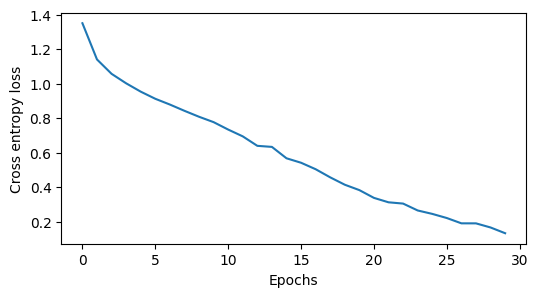

In [11]:
# Instantiate CNN model and offload to device
model_cnn = myCNN().to(device)

# Setup dataloaders
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

# Use CrossEntropyLoss as loss function for classification task
criterion = nn.CrossEntropyLoss()

# Use SGD with Momentum
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0.9)

# Train model
train(model_cnn, 30, optimizer, criterion, trainloader)

**Optimizer:**

Stochastic Gradient Descent with momentum is used with a learning rate of $\epsilon=0.01$ and Momentum of $\alpha=0.9$.

Standard gradient descent use batch size = full dataset to compute the gradient exactly. The update is very slow for large data sets. Pure stochastic gradient descent use one sample per update, producing high variance gradient calculation. Since the gradient of the loss over the dataset is an expectation, it can be estimated efficiently using mini-batches sampled uniformly from the data, in this case, batch size of $m'=64$ is used:

$$
\hat g_k = \frac{1}{m'} \sum_{i=1}^{m'} \nabla_\theta L(f(\mathbf{x}_i; \theta), y_i).
$$

Momentum is added to accumulate an exponentially decaying average of past gradients. It damps oscilations and speed up convergence. The update rule idea is:

$$
 v_{k+1} = \alpha v_k - \epsilon \hat g_k , \quad
\theta_{k+1} = \theta_k + v_{k+1}
$$

where $\alpha v_k$ allow the optimizer to maintain inertia in directions where the gradient consistently points the same way. Then, update the weights $\theta$ by adding the velocity vector.

From the training curve, between Epochs 1-5, the loss drop rapidly. This indicates that the learning rate $\epsilon=0.01$ is high enough to learn features quickly. After that, the curve shows a smooth and consistent descent. There are no sudden spikes or fluctuations, which suggests that the momentum term is successfully stabilising the gradient updates.

**Loss function:**

CrossEntropyLoss is used. This function combines logsoftmax and negative log likelihood loss, making it suitable for multiclass image classification. The goal of training the neural network is to minimse this value.  

For a 5-class problem, a random model has a probability of $1/5 = 0.2$ for the correct class. The expected initial loss is $-\ln(0.2) \approx 1.61$. From the training curve and output message, at Epoch 1, Batch  10, the loss is 1.615, which indicates that the loss function is initialised correctly. After 10 epochs, the loss reduces to small value, which is the correct behaviour.

### Question 6

In [13]:
def accuracy(model, testloader):

    # Set CNN to evaluation mode to turns off dropout / batchnorm
    model.eval()

    # Initialise counters
    classes = testloader.dataset.classes
    class_correct = [0.0] * len(classes)
    class_total = [0.0] * len(classes)
    total_correct = 0
    total_samples = 0

    # Disable gradient calculation to save memory
    with torch.no_grad():
        for data in testloader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)

            # Get the index with max value in output vector
            _, inds = torch.max(outputs, 1)

            # Update total scores
            total_samples += labels.size(0)
            total_correct += (inds == labels).sum().item()

            # Update scores for each class
            for i in range(len(labels)):
                label = labels[i].item()
                class_total[label] += 1
                if inds[i] == labels[i]:
                    class_correct[label] += 1

    # Print results
    for i, class_name in enumerate(classes):
        acc = 100 * class_correct[i] / class_total[i]
        print(f"Accuracy for class '{class_name}': {acc:.2f}%")

    overall_acc = 100 * total_correct / total_samples
    print(f"Overall accuracy: {overall_acc:.2f}%")


In [14]:
accuracy(model_cnn, testloader)

Accuracy for class 'berry': 63.00%
Accuracy for class 'bird': 63.50%
Accuracy for class 'dog': 75.00%
Accuracy for class 'flower': 71.50%
Accuracy for class 'other': 72.00%
Overall accuracy: 69.00%


***

### Part 2: Fine tuning

### Question 1

In [15]:
import shutil

source_dir = './Linnaeus_5_dataset/Linnaeus 5 32X32'
target_dir = './Linnaeus_5_dataset/Linnaeus 5 32X32 small'
classes_to_keep = ['bird', 'dog']
if os.path.exists(target_dir):
    shutil.rmtree(target_dir)
shutil.copytree(source_dir, target_dir)
subsets = ['train', 'test']

for subset in subsets:
    subset_path = os.path.join(target_dir, subset)
    all_classes = os.listdir(subset_path)
    for class_name in all_classes:
        class_path = os.path.join(subset_path, class_name)
        if class_name not in classes_to_keep:
            shutil.rmtree(class_path)

In [16]:
dataset = './Linnaeus_5_dataset/Linnaeus 5 32X32 small'

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset_small = torchvision.datasets.ImageFolder(root=os.path.join(dataset, 'train'), transform=transform)
testset_small = torchvision.datasets.ImageFolder(root=os.path.join(dataset, 'test'), transform=transform)

trainloader_small = torch.utils.data.DataLoader(trainset_small, batch_size=64, shuffle=True)
testloader_small = torch.utils.data.DataLoader(testset_small, batch_size=64, shuffle=False)

### Question 2

In [17]:
class myMLP(nn.Module):
    def __init__(self):
        super(myMLP, self).__init__()

        self.fc1 = nn.Linear(2048, 512) # Input layer
        self.fc2 = nn.Linear(512, 2) # Output layer
        self.log_softmax = nn.LogSoftmax(dim=1) # Input for NLLLoss

    def forward(self, x):
        x = torch.flatten(x, 1) # (Batch_Size, 128, 4, 4) -> (Batch_Size, 2048)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        x = self.log_softmax(x)
        return x

From Part 1, after the final convolutional block, the feature map has shape:

$$
(128,4,4)
$$

When flattened, this becomes:

$$
128\times 4 \times 4 = 2048
$$

Therefore, the MLP requires **2048 input nodes**

From lecture notes, we require that the output of the network is a probability distribution. In classification task, this allow us to predict class with maximum probablility. We can use softmax to output probabilities in the range of $[0,1]$. It is defined as

$$
\text{softmax}_j = \frac{\exp(z_j)}{\sum_{j'=1}^n \exp(z_{j'})}, \quad 1 \le j \le n.
$$

It takes $e$ to the power of the score. This turns negative numbers into small positive numbers and make big numbers big, which emphasize the true label. It divides each individual score by total exponential sum, this ensures the final result adds up to 1.

From PyTorch documentation, NLLLoss expects its input to be the log-probabilities for each class. Therefore, the appropriate nonlinear function at the output layer is LogSoftmax, which computes

$$
\text{LogSoftmax}(x_i)
=\log\left(\frac{\exp(x_i)}{\sum_j\exp(x_j)}\right)
=x_i-\log\left(\sum e^{x_j}\right)
$$

This method is also more numerically stable because it prevent very small probabilities rounding to zero. For example with network output = $[100,0]$

$$
\text{softmax}(x_2)=\frac{e^0}{e^{100} + e^0} \approx0
\\
\text{Log of softmax}(x_2)= \log(0)=\text{undefined}
\\
\text{LogSoftmax}(x_2)=0-\log(e^{100}+e^0)\approx-100
$$

If standard softmax outputs were passed directly to PyTorch NLLoss, it would minimize the negative probability $-p$ rather than the negative log-likelihood $-\log p$, leading to incorrect gradients.

NLLLoss is suitalble for classification task. In Maximum Likelihood Estimation, the goal of training is to maximise the likelihood that the model predicts the correct class $y$ given input $x$. This is equivalent to minimizing the negative log-likelihood $-\log p(y|x)$. Taking logarithm of the probability turns multiplication  into addition, which is easier to compute. Overall, using LogSoftmax + NLLLoss is mathematically equivalent to using CrossEntropyLoss in one operation.

In [18]:
summary(myMLP().to(device), (2048,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                  [-1, 512]       1,049,088
            Linear-2                    [-1, 2]           1,026
        LogSoftmax-3                    [-1, 2]               0
Total params: 1,050,114
Trainable params: 1,050,114
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.00
Params size (MB): 4.01
Estimated Total Size (MB): 4.02
----------------------------------------------------------------


### Question 3

In [19]:
def fine_tune(myCNN, myMLP, nr_epochs, optimizer, criterion, trainloader):

    # Set CNN to evaluation mode to turns off dropout
    myCNN.eval()

    # Set MLP to traininig mode to ensure dropout / batchNorm act correctly
    myMLP.train()

    epoch_loss = []
    for epoch in range(nr_epochs):
        batch_loss = []
        running_loss = 0.0
        for i, data in enumerate(trainloader):
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)

            # Disable gradient calculation for CNN
            with torch.no_grad():
                # Manually do the forward pass of the convolutional blocks
                x = myCNN.pool(F.relu(myCNN.bn1(myCNN.conv1(inputs))))
                x = myCNN.pool(F.relu(myCNN.bn2(myCNN.conv2(x))))
                x = myCNN.pool(F.relu(myCNN.bn3(myCNN.conv3(x))))
                features = x # (batch_size x 128 x 4 x 4)

            # Train MLP
            optimizer.zero_grad()
            output = myMLP(features)
            loss = criterion(output, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.detach().item()
            batch_loss.append(loss.detach().item())

            if i % 10 == 9:
                print(f'[Epoch {epoch + 1}, Batch {i + 1:3d}] loss: {running_loss / 10:.3f}')
                running_loss = 0.0

        # Compute average loss for each epoch
        epoch_loss.append(np.array(batch_loss).mean())

    print('Finished Fine-tuning')
    plt.figure(figsize=(6, 3))
    plt.plot(epoch_loss)
    plt.xlabel('Epochs')
    plt.ylabel('Negative log likelihood loss')
    plt.show()

### Question 4

[Epoch 1, Batch  10] loss: 0.640
[Epoch 1, Batch  20] loss: 0.431
[Epoch 1, Batch  30] loss: 0.324
[Epoch 2, Batch  10] loss: 0.156
[Epoch 2, Batch  20] loss: 0.134
[Epoch 2, Batch  30] loss: 0.105
[Epoch 3, Batch  10] loss: 0.061
[Epoch 3, Batch  20] loss: 0.060
[Epoch 3, Batch  30] loss: 0.046
[Epoch 4, Batch  10] loss: 0.031
[Epoch 4, Batch  20] loss: 0.032
[Epoch 4, Batch  30] loss: 0.030
[Epoch 5, Batch  10] loss: 0.021
[Epoch 5, Batch  20] loss: 0.024
[Epoch 5, Batch  30] loss: 0.022
[Epoch 6, Batch  10] loss: 0.019
[Epoch 6, Batch  20] loss: 0.020
[Epoch 6, Batch  30] loss: 0.014
[Epoch 7, Batch  10] loss: 0.008
[Epoch 7, Batch  20] loss: 0.016
[Epoch 7, Batch  30] loss: 0.011
[Epoch 8, Batch  10] loss: 0.006
[Epoch 8, Batch  20] loss: 0.008
[Epoch 8, Batch  30] loss: 0.006
[Epoch 9, Batch  10] loss: 0.004
[Epoch 9, Batch  20] loss: 0.005
[Epoch 9, Batch  30] loss: 0.004
[Epoch 10, Batch  10] loss: 0.004
[Epoch 10, Batch  20] loss: 0.004
[Epoch 10, Batch  30] loss: 0.004
Finishe

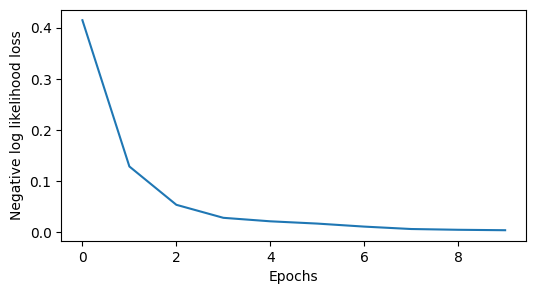

In [35]:
# Instantiate MLP and offload to device
model_mlp = myMLP().to(device)

# Use negative log likelihood loss
criterion_mlp = nn.NLLLoss()

# Only update the MLP weights
optimizer_mlp = torch.optim.SGD(model_mlp.parameters(), lr=0.01, momentum=0.9)

# Run fine-tuning only on bird and dog images
fine_tune(model_cnn, model_mlp, 10, optimizer_mlp, criterion_mlp, trainloader_small)

I didn't run 30 epochs because as seen in the graph above, 10 is enough to reach convergence

### Question 5

In [36]:
def accuracy_fine_tune(myCNN, myMLP, testloader_small):

    # Set CNN and MLP to evaluation mode to turns off dropout
    myCNN.eval()
    myMLP.eval()

    # Initialise counters
    classes = testloader_small.dataset.classes
    class_correct = [0.0] * len(classes)
    class_total = [0.0] * len(classes)
    total_correct = 0
    total_samples = 0

    # Disable gradient calculation to save memory
    with torch.no_grad():
        for data in testloader_small:
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            # Manually do the forward pass of the convolutional blocks
            x = myCNN.pool(F.relu(myCNN.bn1(myCNN.conv1(images))))
            x = myCNN.pool(F.relu(myCNN.bn2(myCNN.conv2(x))))
            x = myCNN.pool(F.relu(myCNN.bn3(myCNN.conv3(x))))
            outputs = myMLP(x)

            # Get the index with max value in output vector
            _, inds = torch.max(outputs, 1)

            # Update total scores
            total_samples += labels.size(0)
            total_correct += (inds == labels).sum().item()

            # Update scores for each class
            for i in range(len(labels)):
                label = labels[i].item()
                class_total[label] += 1
                if inds[i] == labels[i]:
                   class_correct[label] += 1

    # Print Results
    for i, class_name in enumerate(classes):
          acc = 100 * class_correct[i] / class_total[i]
          print(f"Accuracy for class '{class_name}': {acc:.2f}%")

    overall_acc = 100 * total_correct / total_samples
    print(f"Overall accuracy: {overall_acc:.2f}%")


In [37]:
accuracy_fine_tune(model_cnn, model_mlp, testloader_small)

Accuracy for class 'bird': 85.25%
Accuracy for class 'dog': 84.75%
Overall accuracy: 85.00%


The baseline CNN achieves an overall accuracy of 69.00%. The fine-tuned model achieves a 16% improvement of overall accuracy to 85.00%. Bird class accuracy increases from 63.50% to 85.25%, and dog class increases from 75% to 84.75%.

These improvements are consistent with the benefits of transfer learning. The pre-trained CNN model provides a set of low to mid level features that generalise well across visual tasks. Fine-tuning the higher-level layers allows the model to adapt these features to the specific dataset, and hence improve the classfication accuracy.

***
### Part 3: Adversarial attacks

### Question 1

The parameter $\epsilon$ controls the maximum allowable perturbation applied to the input and determines the strength of the adversarial attack. In MI-FGSM, the adversarial example $x^*$ must satisfy $\|x^*-x\|_\infty\leq\epsilon$, meaning that the distance between real and fake pixels can change by at most $\epsilon$. larger $\epsilon$ allows stronger but more detectable perturbations, while a smaller $\epsilon$ produces subtler attacks that may be harder to detect but also less effective.

First, the total noise $\epsilon$ is divided uniformly across $T$ iterations to determine the step size $\alpha$.  Then, initialise the momentum accumulator $g_0 = 0$ and adversarial sequence with original image $x_0^*=x$. At each iteration, the algorithm computes the gradient of the loss with respect to the current adversarial example, $\nabla_{x}J(x_t^*,y)$, which shows the steepest increment to the model’s loss. This gradient is normalised by its $L_1$ norm and combined with the previous accumulated direction using the decay factor $\mu$, yielding an updated momentum term $g_{t+1}$ that smooths the update direction. The momentum term smooths and stabilises successive updates, which improves attack stability and transferability and helps avoid poor local optima. The adversarial input is then updated by moving a step size $\alpha$ in the direction of the sign of $g_{t+1}$, ensuring that each update lies on the $L_\infty$ boundary. Finally, the adversarial example $x_T^*$ is returned.

### Question 2

In [29]:
def adversarial(myCNN, myMLP, image, label, epsilon):
    # Initialise parameters
    T = 10                  # Number of iterations
    mu = 1.0                # Decay factor for momentum
    alpha = epsilon / T     # Step size

    # Add batch dimension (3,32,32) -> (1,3,32,32)
    x_adv = image.unsqueeze(0).to(device)
    x_adv.requires_grad = True # Track gradient for the input image

    # Setup
    y = torch.tensor([label]).to(device)
    g = torch.zeros_like(x_adv) # Initialise momentum vector
    criterion = torch.nn.NLLLoss() # Match myMLP LogSoftmax output

    for t in range(T):
        # Zero out previous gradients
        myCNN.zero_grad()
        myMLP.zero_grad()

        # Manually do the forward pass of the convolutional blocks
        x = myCNN.pool(F.relu(myCNN.bn1(myCNN.conv1(x_adv))))
        x = myCNN.pool(F.relu(myCNN.bn2(myCNN.conv2(x))))
        x = myCNN.pool(F.relu(myCNN.bn3(myCNN.conv3(x))))
        # Pass extracted features to MLP
        features = torch.flatten(x, 1)
        output = myMLP(features)

        # Calculate loss
        loss = criterion(output, y)
        loss.backward()

        # Get the gradient of the loss w.r.t the input image
        grad = x_adv.grad.data

        # Calculate L1 norm of gradient
        grad_l1_norm = torch.norm(grad, p=1)

        # Update momentum
        g = mu * g + grad / grad_l1_norm

        # Update image: x_{t+1} = x_t + alpha * sign(g_{t+1})
        # Use .data to update the tensor without tracking this operation in the graph
        x_adv.data = x_adv.data + alpha * g.sign()

    with torch.no_grad():
        # Manually do the forward pass of the convolutional blocks
        x = myCNN.pool(F.relu(myCNN.bn1(myCNN.conv1(x_adv))))
        x = myCNN.pool(F.relu(myCNN.bn2(myCNN.conv2(x))))
        x = myCNN.pool(F.relu(myCNN.bn3(myCNN.conv3(x))))
        # Pass extracted features to MLP
        features = torch.flatten(x, 1)
        final_output = myMLP(features)

        # Apply softmax to get probability distribution
        probs = F.softmax(final_output, dim=1)

        # Extract probability of the true label
        p = probs[0, label].item()

    # Return the adversarial image and probability of the true label
    # Squeeze to remove batch dimension before returning: (1,3,32,32) -> (3,32,32)
    return x_adv.squeeze(0), p

### Question 3

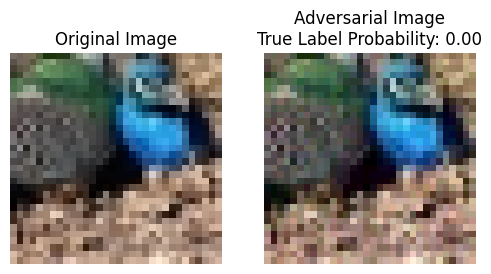

In [38]:
def find_and_plot_adversarial(myCNN, myMLP, testloader_small, epsilon):

    myCNN.eval()
    myMLP.eval()

    bird_idx = 0
    found_successful_attack = False

    for data in testloader_small:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        for i in range(len(labels)):
            img = images[i]
            label = labels[i].item()
            if label != bird_idx:
                continue
            # Check if the fine-tuned model classifies the original image correctly
            with torch.no_grad():
                # Manually do the forward pass of the convolutional blocks of myCNN
                x = myCNN.pool(F.relu(myCNN.bn1(myCNN.conv1(img.unsqueeze(0)))))
                x = myCNN.pool(F.relu(myCNN.bn2(myCNN.conv2(x))))
                x = myCNN.pool(F.relu(myCNN.bn3(myCNN.conv3(x))))
                # Pass extracted features to MLP
                features = torch.flatten(x, 1)
                output = myMLP(features)
                _, inds = torch.max(output, 1)
            if inds.item() != label:
                continue # Skip if model was already wrong

            # Generate adversarial example
            adv_img, prob = adversarial(myCNN, myMLP, img, label, epsilon)

            # Check success condition (p < 0.5)
            if prob < 0.5:
                found_successful_attack = True
                fig, ax = plt.subplots(1, 2, figsize=(6, 4))

                # Prepare Original Image
                plt_img = img * 0.5 + 0.5 # Undo normalisation
                plt_img = plt_img.permute(1, 2, 0).numpy() # Reorder dims (H, W, C)

                # Prepare Adversarial Image
                plt_adv = adv_img * 0.5 + 0.5
                plt_adv = plt_adv.permute(1, 2, 0).detach().numpy()

                # Plot Original
                ax[0].imshow(plt_img)
                ax[0].set_title("Original Image")
                ax[0].axis('off')
                # Plot Adversarial
                ax[1].imshow(plt_adv)
                ax[1].set_title(f"Adversarial Image\nTrue Label Probability: {prob:.2f}")
                ax[1].axis('off')
                plt.show()
                break

        if found_successful_attack:
            break

find_and_plot_adversarial(model_cnn, model_mlp, testloader_small, epsilon=0.05)

It still looks like a bird to me, but my fine-tuned model assigns it a 0.00 probability of being a bird. Hence, the MI-FGSM attack has 100% success rate for this sample

### Question 4

In [44]:
def accuracy_adversarial(myCNN, myMLP, testloader_small, epsilon):
    # Set models to evaluation mode
    myCNN.eval()
    myMLP.eval()

    # Initialise counters
    total_correct = 0
    total_attacked = 0

    for data in testloader_small:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        for i in range(len(labels)):
            img = images[i]
            label = labels[i].item()
            # Disable gradient for this part only, adversarial still need it
            with torch.no_grad():
                # Manually do the forward pass of the convolutional blocks
                x = myCNN.pool(F.relu(myCNN.conv1(img.unsqueeze(0))))
                x = myCNN.pool(F.relu(myCNN.conv2(x)))
                x = myCNN.pool(F.relu(myCNN.conv3(x)))
                # Pass extracted features to MLP
                features = torch.flatten(x, 1)
                output = myMLP(features)
                _, inds = torch.max(output, 1)

            # Attack if the model was originally correct
            if inds.item() == label:
                total_correct += 1
                # Generate adversarial example and returns the probability of the true label
                _, prob = adversarial(myCNN, myMLP, img, label, epsilon)
                # Check if the attack was successful
                if prob < 0.5:
                    total_attacked += 1

    return total_attacked / total_correct

In [45]:
epsilon = 0.05
success_rate = accuracy_adversarial(model_cnn, model_mlp, testloader, epsilon)
print(f"Success Rate: {success_rate * 100:.2f}%")

Success Rate: 90.77%


### Question 5

In [54]:
epsilons = [0.02, 0.04, 0.06, 0.08, 0.1]
success_rates = []

for eps in epsilons:
    rate = accuracy_adversarial(model_cnn, model_mlp, testloader, eps)
    success_rates.append(rate)
    print(f"Epsilon: {eps}, Success Rate: {rate*100:.2f}%")


Epsilon: 0.02, Success Rate: 59.35%
Epsilon: 0.04, Success Rate: 84.79%
Epsilon: 0.06, Success Rate: 95.26%
Epsilon: 0.08, Success Rate: 98.25%
Epsilon: 0.1, Success Rate: 99.25%


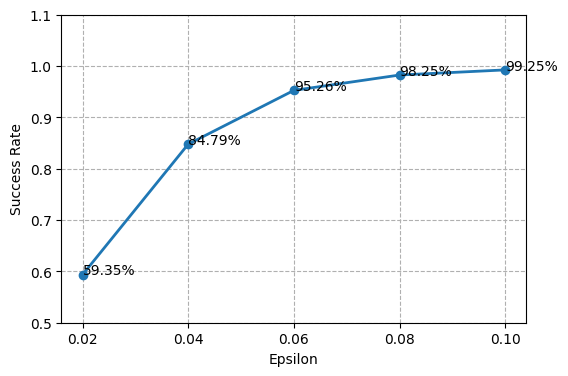

In [57]:
plt.figure(figsize=(6, 4))
plt.plot(epsilons, success_rates, marker='o', linewidth=2)
for x, y in zip(epsilons, success_rates):
    plt.text(x, y, f"{y*100:.2f}%")
plt.xlabel('Epsilon')
plt.ylabel('Success Rate')
plt.grid(True, linestyle='--')
plt.xticks(epsilons)
plt.ylim(0.5, 1.1)
plt.show()

The results show that as epsilon increases, the MI-FGSM algorithm becomes increasingly capable of forcing the model into misclassification.

At lowest epsilon = 0.02, the attack already achieves close to 59% success rate. This indicates that the model is highly vulnerable to even minimal adversarial noise.

Between epsilon = 0.02 and 0.04, the sucess rate increases sharply from 59% to 84%. This implies that for this specific dataset and model, epsilon = 0.04 is roughly the threshold where the attack becomes very effective.

At epsilon = 0.06, the curve begins to saturate. At epsilon = 0.08 and 0.10, the attack achieves close to 100% success rate. This shows that once epsilon is sufficeintly large, MI-FGSM can generate effective adversarial examples for essentially all inputs. Increasing epsilon only yields diminishing returns while the adversarial noise becomes visible and obvious to the human eye.